In [7]:
import time, math, random, statistics
import pandas as pd

lahore_graph = {
    "Lahore_Station": {"Gulberg": 8, "Data_Darbar": 5, "Allama_Iqbal_Airport": 15},
    "Gulberg": {"Lahore_Station": 8, "DHA": 6, "Liberty_Market": 3},
    "DHA": {"Gulberg": 6, "Emporium_Mall": 9, "Bahria_Town": 12},
    "Data_Darbar": {"Lahore_Station": 5, "Badshahi_Mosque": 4, "Walled_City": 2},
    "Allama_Iqbal_Airport": {"Lahore_Station": 15},   # No-fly zone
    "Liberty_Market": {"Gulberg": 3, "Emporium_Mall": 7},
    "Badshahi_Mosque": {"Data_Darbar": 4, "Walled_City": 1},
    "Walled_City": {"Data_Darbar": 2, "Badshahi_Mosque": 1},
    "Emporium_Mall": {"DHA": 9, "Liberty_Market": 7, "Bahria_Town": 8},
    "Bahria_Town": {"DHA": 12, "Emporium_Mall": 8},
}

heuristic = {
    "Lahore_Station": 10, "Gulberg": 5, "DHA": 3, "Data_Darbar": 12,
    "Allama_Iqbal_Airport": 18, "Liberty_Market": 4, "Badshahi_Mosque": 15,
    "Walled_City": 14, "Emporium_Mall": 0, "Bahria_Town": 6,
}

START, GOAL = "Lahore_Station", "Emporium_Mall"

# ---- Constraints / parameters ----
NO_FLY          = {"Allama_Iqbal_Airport"}                    # 5 km no-fly zone
WALLED_CITY     = {"Data_Darbar", "Walled_City", "Badshahi_Mosque"}
MAX_RANGE_KM    = 25      # km per full charge (no payload)
PAYLOAD_DRAIN   = 0.12    # +12% battery drain per kg
TRAFFIC_PENALTY = 0.20    # +20% time through Walled City
SPEED_KMH       = 40      # assumed drone speed

In [9]:
class Conditions:
    """Holds dynamic traffic multipliers per edge (Bonus +1)."""
    def __init__(self):
        self.edge_mult = {}   # frozenset({u, v}) -> multiplier

def battery_pct(dist_km, payload_kg):
    """Battery % used. Drain per km is scaled by (1 + 0.12 * payload)."""
    return dist_km * (1 + PAYLOAD_DRAIN * payload_kg) / MAX_RANGE_KM * 100

def evaluate(path, payload, cond):
    dist = sum(lahore_graph[a][b] for a, b in zip(path, path[1:]))
    weighted = sum(lahore_graph[a][b] * cond.edge_mult.get(frozenset((a, b)), 1.0)
                   for a, b in zip(path, path[1:]))
    if any(n in WALLED_CITY for n in path):          # static traffic penalty
        weighted *= (1 + TRAFFIC_PENALTY)
    time_min = weighted / SPEED_KMH * 60
    batt = battery_pct(dist, payload)
    nofly = any(n in NO_FLY for n in path)
    feasible = batt <= 100 and not nofly
    cost = weighted + 10 * max(0, batt - 100) + (1000 if nofly else 0)
    return {"route": " -> ".join(path), "distance_km": dist,
            "battery_pct": round(batt, 1), "time_min": round(time_min, 1),
            "feasible": feasible, "cost": cost}

In [10]:
def calculate_cost(path, payload_kg=3):
    """Starter-code helper: cost of a path (uses the evaluate() model above)."""
    return evaluate(path, payload_kg, Conditions())["cost"]

In [11]:
def simple_paths(a, b, banned, limit=8):
    """All simple paths a->b avoiding no-fly nodes and banned nodes."""
    out = []
    def dfs(node, path):
        if node == b:
            out.append(path[:]); return
        if len(path) > limit: return
        for nxt in lahore_graph[node]:
            if nxt in NO_FLY or nxt in banned or nxt in path: continue
            path.append(nxt); dfs(nxt, path); path.pop()
    dfs(a, [a])
    return out

def all_neighbors(path):
    """Neighbour = path with one segment re-routed."""
    res = set()
    for i in range(len(path) - 1):
        for j in range(i + 1, len(path)):
            banned = set(path[:i]) | set(path[j + 1:])
            for seg in simple_paths(path[i], path[j], banned):
                new = tuple(path[:i] + seg + path[j + 1:])
                if new != tuple(path):
                    res.add(new)
    return [list(p) for p in res]

def random_neighbor(path):
    nb = all_neighbors(path)
    return random.choice(nb) if nb else path

def random_initial():
    return random.choice(simple_paths(START, GOAL, set()))

def greedy_initial():
    """Heuristic-guided start: always step to the neighbour with lowest h(n)."""
    path = [START]
    while path[-1] != GOAL:
        cands = [n for n in lahore_graph[path[-1]] if n not in path and n not in NO_FLY]
        if not cands:
            return random_initial()
        path.append(min(cands, key=lambda n: heuristic[n]))
    return path

In [12]:
def hill_climbing(payload=3, cond=None, restarts=3, seed=None):
    if seed is not None: random.seed(seed)
    cond = cond or Conditions()
    f = lambda p: evaluate(p, payload, cond)["cost"]
    t0 = time.perf_counter()

    starts = [greedy_initial()] + [random_initial() for _ in range(restarts)]
    best = None
    for cur in starts:
        while True:                                  # steepest-ascent
            nbrs = all_neighbors(cur)
            if not nbrs: break
            cand = min(nbrs, key=f)
            if f(cand) < f(cur): cur = cand
            else: break                              # local optimum
        if best is None or f(cur) < f(best): best = cur

    res = evaluate(best, payload, cond)
    res["runtime_ms"] = (time.perf_counter() - t0) * 1000
    res["path"] = best
    return res

def show(name, r):
    print(f"--- {name} ---")
    for k in ["route", "distance_km", "battery_pct", "time_min", "feasible", "runtime_ms"]:
        if k not in r:          # FIX: skip keys that a result doesn't have
            continue
        v = round(r[k], 3) if k == "runtime_ms" else r[k]
        print(f"{k:12}: {v}")
    print()

# Pure greedy start (shows why plain heuristic-following is not enough)
show("Greedy heuristic start (3 kg)", evaluate(greedy_initial(), 3, Conditions()))

# Task 1 result
hc = hill_climbing(payload=3, seed=42)
show("Hill Climbing (3 kg)", hc)

--- Greedy heuristic start (3 kg) ---
route       : Lahore_Station -> Gulberg -> DHA -> Emporium_Mall
distance_km : 23
battery_pct : 125.1
time_min    : 34.5
feasible    : False

--- Hill Climbing (3 kg) ---
route       : Lahore_Station -> Gulberg -> Liberty_Market -> Emporium_Mall
distance_km : 18
battery_pct : 97.9
time_min    : 27.0
feasible    : True
runtime_ms  : 2.044



In [13]:
def simulated_annealing(payload=3, cond=None, T0=50, Tmin=0.01, alpha=0.9,
                        iters_per_T=15, seed=None, on_step=None):
    if seed is not None: random.seed(seed)
    cond = cond or Conditions()
    f = lambda p: evaluate(p, payload, cond)["cost"]   # reads live traffic
    t0 = time.perf_counter()

    cur = random_initial(); best = cur
    T, step = T0, 0
    while T > Tmin:
        for _ in range(iters_per_T):
            step += 1
            if on_step: on_step(step, cond, cur)       # dynamic traffic hook
            cand = random_neighbor(cur)
            delta = f(cand) - f(cur)
            if delta < 0 or random.random() < math.exp(-delta / T):
                cur = cand
            if f(cur) < f(best): best = cur
        T *= alpha
    if f(cur) < f(best): best = cur

    res = evaluate(best, payload, cond)
    res["runtime_ms"] = (time.perf_counter() - t0) * 1000
    res["path"] = best
    return res

sa = simulated_annealing(payload=3, seed=42)
show("Simulated Annealing (3 kg)", sa)

--- Simulated Annealing (3 kg) ---
route       : Lahore_Station -> Gulberg -> Liberty_Market -> Emporium_Mall
distance_km : 18
battery_pct : 97.9
time_min    : 27.0
feasible    : True
runtime_ms  : 369.066



In [14]:
rows = []
for payload in [2, 3, 4, 5]:
    for name, fn in [("Hill Climbing", hill_climbing), ("Simulated Annealing", simulated_annealing)]:
        runs = [fn(payload=payload, seed=s) for s in range(10)]
        best = min(runs, key=lambda r: r["cost"])
        rows.append({
            "Payload (kg)": payload,
            "Algorithm": name,
            "Route": best["route"],
            "Distance (km)": best["distance_km"],
            "Battery (%)": best["battery_pct"],
            "Delivery time (min)": best["time_min"],
            "Feasible": best["feasible"],
            "Avg runtime (ms)": round(statistics.mean(r["runtime_ms"] for r in runs), 2),
            "Found optimum (%)": 100 * sum(r["cost"] == best["cost"] for r in runs) // len(runs),
        })

df = pd.DataFrame(rows)
df
print(df.to_string(index=False))

 Payload (kg)           Algorithm                                                        Route  Distance (km)  Battery (%)  Delivery time (min)  Feasible  Avg runtime (ms)  Found optimum (%)
            2       Hill Climbing Lahore_Station -> Gulberg -> Liberty_Market -> Emporium_Mall             18         89.3                 27.0      True              3.73                100
            2 Simulated Annealing Lahore_Station -> Gulberg -> Liberty_Market -> Emporium_Mall             18         89.3                 27.0      True            394.19                100
            3       Hill Climbing Lahore_Station -> Gulberg -> Liberty_Market -> Emporium_Mall             18         97.9                 27.0      True              0.65                100
            3 Simulated Annealing Lahore_Station -> Gulberg -> Liberty_Market -> Emporium_Mall             18         97.9                 27.0      True            197.81                100
            4       Hill Climbing Lahore_Stat

In [15]:
def check_constraints(path, payload):
    r = evaluate(path, payload, Conditions())
    return {
        "starts/ends correctly": path[0] == START and path[-1] == GOAL,
        "valid edges only": all(b in lahore_graph[a] for a, b in zip(path, path[1:])),
        "avoids no-fly zone": not any(n in NO_FLY for n in path),
        "battery <= 100%": r["battery_pct"] <= 100,
        "passes Walled City (+20% time)": any(n in WALLED_CITY for n in path),
    }

rows = []
for payload in [2, 3, 4, 5]:
    for name, fn in [("Hill Climbing", hill_climbing), ("Simulated Annealing", simulated_annealing)]:
        best = min((fn(payload=payload, seed=s) for s in range(10)), key=lambda r: r["cost"])
        chk = check_constraints(best["path"], payload)
        rows.append({"Payload (kg)": payload, "Algorithm": name,
                     "Battery (%)": best["battery_pct"],
                     **{k: (("yes" if v else "no") if k.startswith("passes") else ("PASS" if v else "FAIL")) for k, v in chk.items()},
                     "All hard constraints met": all(v for k, v in chk.items() if k != "passes Walled City (+20% time)")})
chk_df = pd.DataFrame(rows)
print(chk_df.to_string(index=False))

 Payload (kg)           Algorithm  Battery (%) starts/ends correctly valid edges only avoids no-fly zone battery <= 100% passes Walled City (+20% time)  All hard constraints met
            2       Hill Climbing         89.3                  PASS             PASS               PASS            PASS                             no                      True
            2 Simulated Annealing         89.3                  PASS             PASS               PASS            PASS                             no                      True
            3       Hill Climbing         97.9                  PASS             PASS               PASS            PASS                             no                      True
            3 Simulated Annealing         97.9                  PASS             PASS               PASS            PASS                             no                      True
            4       Hill Climbing        106.6                  PASS             PASS               PASS      

In [16]:
import folium

# Approximate coordinates (illustrative; map distances won't match graph km exactly)
coords = {
    "Lahore_Station": (31.5774, 74.3300), "Gulberg": (31.5204, 74.3487),
    "DHA": (31.4697, 74.4101), "Data_Darbar": (31.5790, 74.3150),
    "Allama_Iqbal_Airport": (31.5216, 74.4036), "Liberty_Market": (31.5124, 74.3438),
    "Badshahi_Mosque": (31.5882, 74.3103), "Walled_City": (31.5826, 74.3250),
    "Emporium_Mall": (31.4675, 74.2655), "Bahria_Town": (31.3680, 74.1850),
}

def draw_map(routes, fname="lahore_routes.html"):
    """routes: dict {label: (path, color)}"""
    m = folium.Map(location=[31.52, 74.33], zoom_start=11, tiles="OpenStreetMap")

    # all graph edges (grey)
    for u, nbrs in lahore_graph.items():
        for v, d in nbrs.items():
            if u < v:
                folium.PolyLine([coords[u], coords[v]], color="lightgray",
                                weight=2, tooltip=f"{u}-{v}: {d} km").add_to(m)

    # no-fly zone (5 km) and Walled City traffic zone
    folium.Circle(coords["Allama_Iqbal_Airport"], radius=5000, color="red",
                  fill=True, fill_opacity=0.25, tooltip="No-fly zone (5 km)").add_to(m)
    folium.Circle(coords["Walled_City"], radius=1500, color="orange",
                  fill=True, fill_opacity=0.2, tooltip="Walled City (+20% time)").add_to(m)

    for name, (lat, lon) in coords.items():
        color = "green" if name == START else "darkred" if name == GOAL else "blue"
        folium.Marker((lat, lon), tooltip=name.replace("_", " "),
                      icon=folium.Icon(color=color, icon="info-sign")).add_to(m)

    for label, (path, color) in routes.items():
        folium.PolyLine([coords[n] for n in path], color=color, weight=6,
                        opacity=0.8, tooltip=label).add_to(m)

    folium.LayerControl().add_to(m)
    m.save(fname)
    return m

draw_map({"Hill Climbing": (hc["path"], "green"),
          "Simulated Annealing": (sa["path"], "purple")})

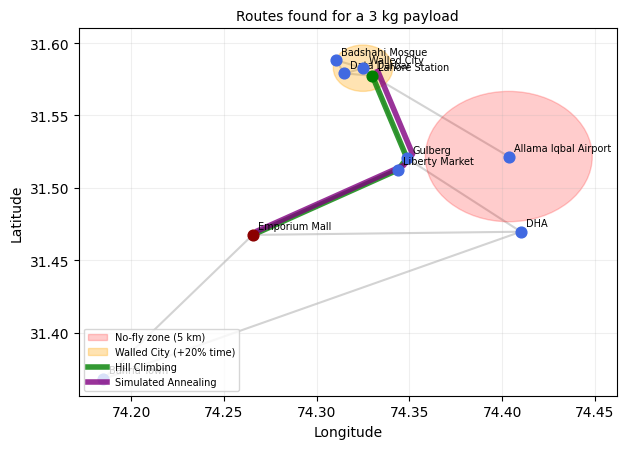

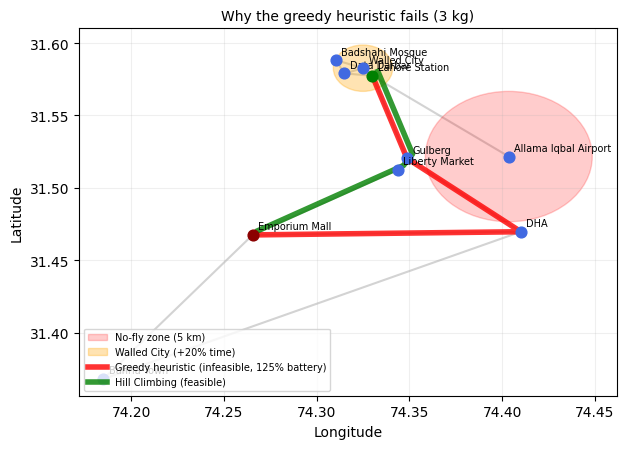

In [17]:
import matplotlib.pyplot as plt

def plot_routes(routes, title, fname):
    fig, ax = plt.subplots(figsize=(6.4, 4.6))
    for u, nbrs in lahore_graph.items():
        for v in nbrs:
            if u < v:
                ax.plot([coords[u][1], coords[v][1]], [coords[u][0], coords[v][0]], color="lightgray", lw=1.5, zorder=1)
    ax.add_patch(plt.Circle((coords["Allama_Iqbal_Airport"][1], coords["Allama_Iqbal_Airport"][0]), 0.045,
                            color="red", alpha=0.2, label="No-fly zone (5 km)"))
    ax.add_patch(plt.Circle((coords["Walled_City"][1], coords["Walled_City"][0]), 0.016,
                            color="orange", alpha=0.3, label="Walled City (+20% time)"))
    for label, (path, color, off) in routes.items():
        ax.plot([coords[n][1] + off for n in path], [coords[n][0] + off for n in path],
                color=color, lw=4, alpha=0.8, label=label, zorder=2)
    for n, (la, lo) in coords.items():
        c = "green" if n == START else "darkred" if n == GOAL else "royalblue"
        ax.scatter(lo, la, color=c, s=60, zorder=3)
        ax.annotate(n.replace("_", " "), (lo, la), fontsize=7, xytext=(4, 4), textcoords="offset points")
    ax.set_title(title, fontsize=10); ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
    ax.legend(fontsize=7, loc="lower left"); ax.grid(alpha=0.2)
    fig.tight_layout(); fig.savefig(fname, dpi=160); plt.show()

plot_routes({"Hill Climbing": (hc["path"], "green", 0.0), "Simulated Annealing": (sa["path"], "purple", 0.003)},
            "Routes found for a 3 kg payload", "route_3kg.png")
plot_routes({"Greedy heuristic (infeasible, 125% battery)": (greedy_initial(), "red", 0.0),
             "Hill Climbing (feasible)": (hc["path"], "green", 0.003)},
            "Why the greedy heuristic fails (3 kg)", "route_greedy_vs_hc.png")

In [18]:
def make_dynamic_events():
    log = []
    def on_step(step, cond, cur):
        # Step 300: Gulberg-Liberty road becomes heavily congested/closed
        if step == 300:
            cond.edge_mult[frozenset(("Gulberg", "Liberty_Market"))] = 1000
            log.append((step, "CONGESTION on Gulberg-Liberty_Market", " -> ".join(cur)))
        # Step 700: traffic clears
        if step == 700:
            cond.edge_mult.clear()
            log.append((step, "Traffic CLEARED", " -> ".join(cur)))
    return on_step, log

on_step, log = make_dynamic_events()
dyn = simulated_annealing(payload=3, seed=7, on_step=on_step)

print("Route in use when each event fired:")
for step, event, route in log:
    print(f"  step {step}: {event}\n     current route: {route}")
show("SA with dynamic traffic (final)", dyn)

draw_map({"SA (dynamic traffic)": (dyn["path"], "orange")}, "lahore_dynamic.html")

Route in use when each event fired:
  step 300: CONGESTION on Gulberg-Liberty_Market
     current route: Lahore_Station -> Gulberg -> Liberty_Market -> Emporium_Mall
  step 700: Traffic CLEARED
     current route: Lahore_Station -> Gulberg -> DHA -> Emporium_Mall
--- SA with dynamic traffic (final) ---
route       : Lahore_Station -> Gulberg -> Liberty_Market -> Emporium_Mall
distance_km : 18
battery_pct : 97.9
time_min    : 27.0
feasible    : True
runtime_ms  : 318.813

